# Лабораторная работа №1 — регрессия: Wine Quality

**Датасет:** UCI Wine Quality, белое вино (4898 образцов, 11 химических признаков, целевая оценка `quality`).  
**Цель:** сравнить константный baseline, линейную регрессию, случайный лес и градиентный бустинг по RMSE и MAE; проанализировать важность признаков и ошибки. **Целевой порог: RMSE < 0.70.**

Данные скачиваются **онлайн** при выполнении ноутбука из UCI и сохраняются рядом с ним (`winequality-white.csv`). Если нет доступа к сети, положите CSV в ту же папку вручную. Источник: https://archive.ics.uci.edu/dataset/186/wine+quality .

> Принцип честной оценки: настройки моделей выбираются **только кросс-валидацией на train**; `test` используется для окончательного сравнения и последующего описательного анализа ошибок, а не для подбора гиперпараметров. Порог на собственной тестовой выборке не гарантирует такую же оценку на скрытой выборке преподавателя.

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Онлайн-загрузка и знакомство с данными

Используем **белое вино** (не смешиваем красное и белое). Признаки — химические измерения, `quality` — субъективная экспертная оценка. Это регрессия, поскольку модель предсказывает численное значение оценки.

In [2]:
DATA_FILE = Path("winequality-white.csv")
DATA_URLS = [
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
    "https://archive.ics.uci.edu/static/public/186/wine+quality.zip",
]

if not DATA_FILE.exists():
    loaded = False
    for url in DATA_URLS:
        try:
            print("Загружаем:", url)
            response = requests.get(url, timeout=35)
            response.raise_for_status()
            if url.endswith(".zip"):
                import zipfile
                with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
                    content = archive.read("winequality-white.csv")
            else:
                content = response.content
            test_df = pd.read_csv(io.BytesIO(content), sep=";")
            assert test_df.shape == (4898, 12) and "quality" in test_df.columns
            DATA_FILE.write_bytes(content)
            loaded = True
            break
        except Exception as e:
            print("Не удалось скачать:", type(e).__name__, str(e)[:150])
    if not loaded:
        raise FileNotFoundError("Нет доступа к UCI. Скачайте winequality-white.csv по ссылке в начале ноутбука и положите рядом с .ipynb")

df = pd.read_csv(DATA_FILE, sep=";")
assert df.shape == (4898, 12), f"Неожиданный размер: {df.shape}"
assert "quality" in df
print("Размер:", df.shape)
display(df.head())
display(df.describe().T.round(3))
print("Пропуски по столбцам:\n", df.isna().sum())
print("Дубликаты строк:", df.duplicated().sum())
print("Типы столбцов:\n", df.dtypes)

Загружаем: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv
Размер: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.300,14.200
volatile acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.320,1.100
citric acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.390,1.660
residual sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.900,65.800
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.050,0.346
free sulfur dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.000,289.000
total sulfur dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.000,440.000
density,4898.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.280,3.820
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.550,1.080


Пропуски по столбцам:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Дубликаты строк: 937
Типы столбцов:
 fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


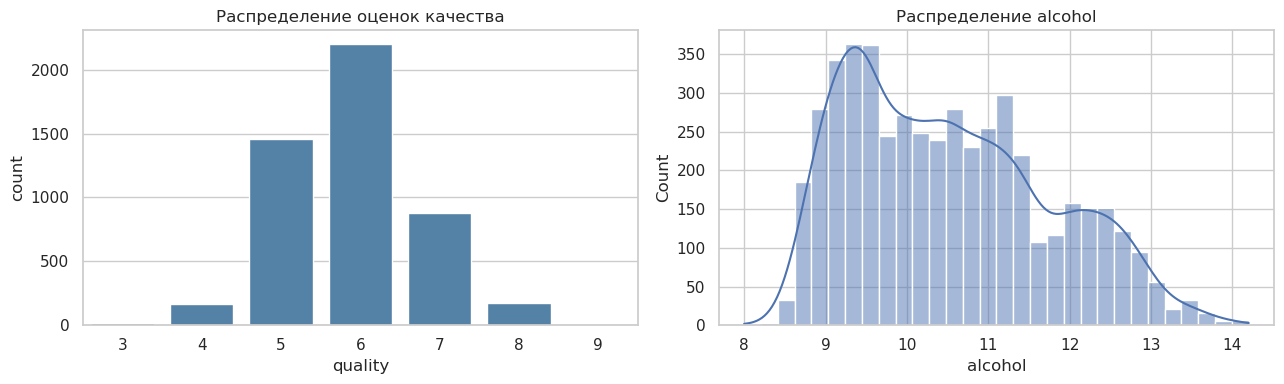

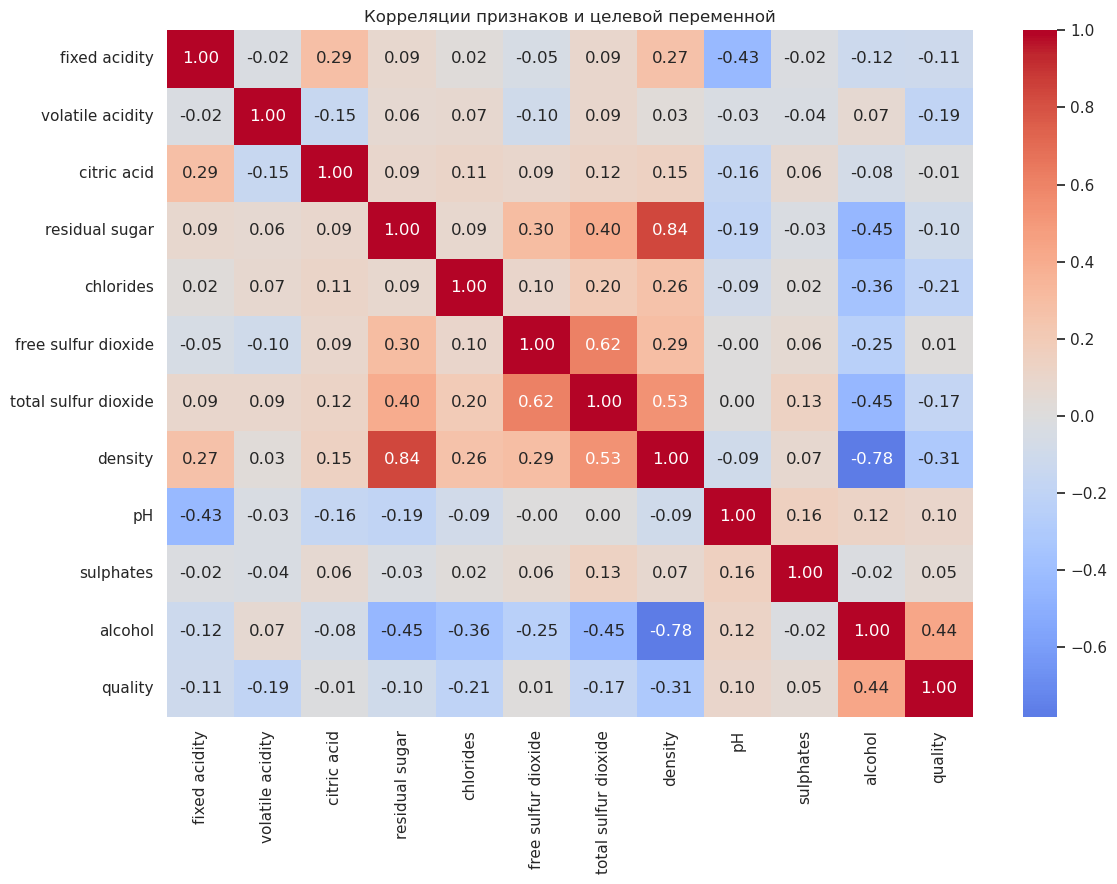

,corr_with_quality
alcohol,0.436
density,-0.307
chlorides,-0.210
volatile acidity,-0.195
total sulfur dioxide,-0.175
fixed acidity,-0.114
pH,0.099
residual sugar,-0.098
sulphates,0.054
citric acid,-0.009


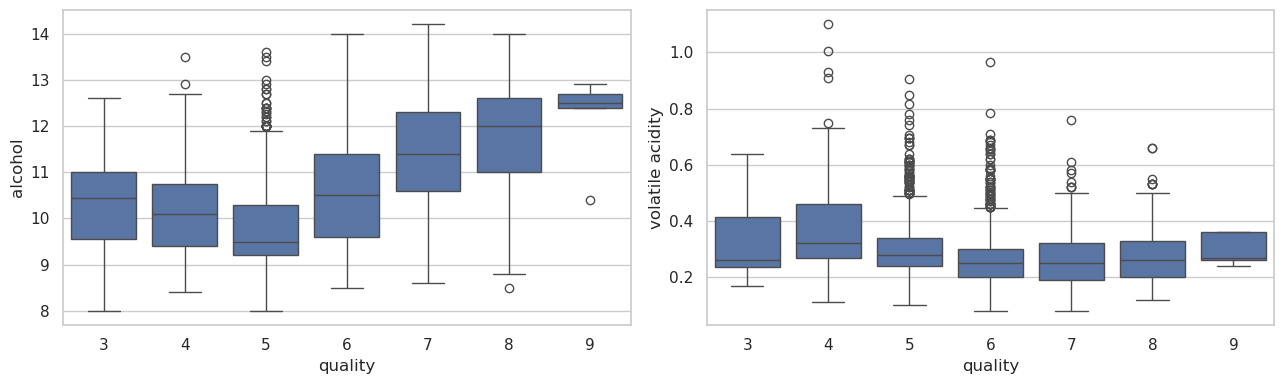

Вывод: Самая выраженная линейная связь с качеством: alcohol (r=+0.436).
Важно: корреляция не является доказательством причинности. Оценки качества несбалансированы; крайние значения представлены редко.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
sns.countplot(data=df, x="quality", ax=ax[0], color="steelblue")
ax[0].set_title("Распределение оценок качества")
sns.histplot(df["alcohol"], bins=30, kde=True, ax=ax[1])
ax[1].set_title("Распределение alcohol")
plt.tight_layout();plt.show()

corr = df.corr(numeric_only=True)
plt.figure(figsize=(12,9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Корреляции признаков и целевой переменной")
plt.tight_layout(); plt.show()
quality_corr = corr["quality"].drop("quality").sort_values(key=abs, ascending=False)
display(quality_corr.to_frame("corr_with_quality").round(3))
fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.boxplot(data=df, x="quality", y="alcohol", ax=axes[0])
sns.boxplot(data=df, x="quality", y="volatile acidity", ax=axes[1])
plt.tight_layout();plt.show()
print("Вывод: Самая выраженная линейная связь с качеством:", quality_corr.index[0],
      f"(r={quality_corr.iloc[0]:+.3f}).")
print("Важно: корреляция не является доказательством причинности. Оценки качества несбалансированы; крайние значения представлены редко.")

### Вывод по EDA

- **Частоты `quality`** позволяют увидеть дисбаланс: средние оценки встречаются чаще крайних. Модель может хуже предсказывать редкие оценки.
- **Матрица корреляций** показывает направление линейной связи; сильная корреляция полезна как сигнал, но не гарантирует причинной зависимости или наибольшего вклада в нелинейной модели.
- **Масштабы разных признаков** различаются: для сопоставления коэффициентов линейной регрессии применим `StandardScaler` внутри `Pipeline`. Для деревьев стандартное масштабирование обычно не требуется.
- **Дубликаты** могут отражать повторные или идентичные измерения. В задании не указан протокол дедупликации, поэтому сохраняем данные как опубликованы; дубликаты между train и test могут слегка завысить оценку обобщения. В строгом групповом сценарии потребовалось бы разбиение с учётом повторов.

## 2. Подготовка выборок

**80% train / 20% test**, фиксированный `random_state=42`. `stratify=quality` сохраняет распределение редких оценок в обоих наборах. Отдельная тестовая выборка применяется только после выбора настроек моделей. Многократный выбор алгоритма по test ведёт к **утечке информации через подбор на тесте** и завышает ожидаемое качество на новых данных.

In [4]:
X = df.drop(columns="quality")
y = df["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print("train:", X_train.shape, "test:", X_test.shape)
print("Доли quality (%), train / test:")
display(pd.concat([y_train.value_counts(normalize=True).sort_index().rename("train"),
                   y_test.value_counts(normalize=True).sort_index().rename("test")], axis=1).mul(100).round(1))

train: (3918, 11) test: (980, 11)
Доли quality (%), train / test:


,train,test
quality,,
3,0.4,0.4
4,3.3,3.4
5,29.8,29.7
6,44.9,44.9
7,18.0,18.0
8,3.6,3.6
9,0.1,0.1


## 3. Метрики и baseline

**MAE** — средняя абсолютная ошибка в баллах `quality`, устойчива относительно RMSE к единичным большим отклонениям. **RMSE** — корень из среднего квадрата ошибки; возведение в квадрат делает крупные промахи более значимыми. При нескольких больших ошибках RMSE может заметно превышать MAE. Константа, оптимальная для среднеквадратичной ошибки, — **среднее `quality` по train**, без обращения к test.

In [5]:
def evaluate(y_true, predictions):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
            "MAE": mean_absolute_error(y_true, predictions)}

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("Константа baseline:", baseline.constant_.item())
print("Train baseline:", evaluate(y_train, baseline.predict(X_train)))

Константа baseline: 5.877998979070955
Train baseline: {'RMSE': 0.8854336389263151, 'MAE': 0.6707170293726862}


## 4. Модели и подбор по train-only CV

Для всех моделей одинаковые 5 фолдов `KFold(shuffle=True, random_state=42)` и метрика подбора `neg_root_mean_squared_error`. Сопоставление идёт по среднему CV-RMSE. Подбор не использует `y_test`.

Дополнительно проверяем `ExtraTreesRegressor` как опциональный конкурент для достижения порога — он **не заменяет** три обязательные модели. Для случайного леса и бустинга несколько комбинаций параметров проверяются на CV. Время выполнения зависит от компьютера.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"rmse":"neg_root_mean_squared_error", "mae":"neg_mean_absolute_error"}
models = {}
cv_rows = []

def record_cv(name, estimator):
    result = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({"Модель": name, "CV RMSE": -result["test_rmse"].mean(),
                    "CV MAE": -result["test_mae"].mean(),
                    "CV RMSE std": result["test_rmse"].std()})
    models[name] = estimator

record_cv("Baseline", DummyRegressor(strategy="mean"))
record_cv("Linear Regression", make_pipeline(StandardScaler(), LinearRegression()))
print(pd.DataFrame(cv_rows).round(4).to_string(index=False))

           Модель  CV RMSE  CV MAE  CV RMSE std
         Baseline   0.8854  0.6708       0.0091
Linear Regression   0.7526  0.5843       0.0148


In [7]:
# Параметры подбираются на TRAIN. Во всех GridSearchCV refit=True.
search_configs = {
    "Random Forest": (
        RandomForestRegressor(random_state=SEED, n_jobs=1),
        {"n_estimators": [300, 500], "max_features": [0.7, 1.0], "min_samples_leaf": [1, 2]}
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=SEED),
        {"n_estimators": [200, 400], "learning_rate": [0.04, 0.08],
         "max_depth": [2, 3], "subsample": [0.85]}
    ),
    "Extra Trees (дополнительно)": (
        ExtraTreesRegressor(random_state=SEED, n_jobs=1),
        {"n_estimators": [350, 550], "min_samples_leaf": [1, 2], "max_features": [0.8, 1.0]}
    )
}
for name, (estimator, param_grid) in search_configs.items():
    print("Подбор:", name)
    search = GridSearchCV(estimator, param_grid, cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    cv_rows.append({"Модель": name, "CV RMSE": -search.best_score_,
                    "CV MAE": np.nan, "CV RMSE std": np.nan})
    print("Лучшие параметры:", search.best_params_, "CV RMSE:", round(-search.best_score_,4))
cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE")
display(cv_table.round(4))
selected_name = cv_table.iloc[0]["Модель"]
print("Победитель ТОЛЬКО по train CV:", selected_name)

Подбор: Random Forest
Лучшие параметры: {'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 500} CV RMSE: 0.6259
Подбор: Gradient Boosting
Лучшие параметры: {'learning_rate': 0.08, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.85} CV RMSE: 0.6771
Подбор: Extra Trees (дополнительно)
Лучшие параметры: {'max_features': 0.8, 'min_samples_leaf': 1, 'n_estimators': 550} CV RMSE: 0.6093


,Модель,CV RMSE,CV MAE,CV RMSE std
4,Extra Trees (дополнительно),0.6093,NaN,NaN
2,Random Forest,0.6259,NaN,NaN
3,Gradient Boosting,0.6771,NaN,NaN
1,Linear Regression,0.7526,0.5843,0.0148
0,Baseline,0.8854,0.6708,0.0091


Победитель ТОЛЬКО по train CV: Extra Trees (дополнительно)


## 5. Финальная оценка на единой тестовой выборке

После выбора конфигураций мы обучаем обязательные модели на **всём train** и один раз вычисляем RMSE и MAE на **одном test**. Не перенастраиваем параметры по результатам таблицы.

In [8]:
test_rows = []
test_predictions = {}
fitted_models = {}
for name in ["Baseline", "Linear Regression", "Random Forest", "Gradient Boosting", "Extra Trees (дополнительно)"]:
    estimator = models[name]
    estimator.fit(X_train, y_train)
    preds = estimator.predict(X_test)
    test_predictions[name] = preds
    fitted_models[name] = estimator
    test_rows.append({"Модель": name, **evaluate(y_test, preds)})
results = pd.DataFrame(test_rows).sort_values("RMSE", ascending=True).reset_index(drop=True)
display(results.style.format({"RMSE":"{:.4f}","MAE":"{:.4f}"}))
baseline_rmse = results.loc[results["Модель"]=="Baseline", "RMSE"].iloc[0]
print("Превзошли baseline:", results.loc[results.RMSE < baseline_rmse, "Модель"].tolist())
print("Обязательные модели: лучший test-RMSE:",
      results[results["Модель"].isin(["Linear Regression","Random Forest","Gradient Boosting"])].iloc[0]["Модель"])
print("Порог RMSE < 0.70 у модели, выбранной по CV:",
      evaluate(y_test, test_predictions[selected_name])["RMSE"] < 0.70)
print("Модель, заранее выбранная по CV:", selected_name)
print("Важно: результаты собственной тестовой выборки не гарантируют RMSE на скрытом тесте.")

,Модель,RMSE,MAE
0,Extra Trees (дополнительно),0.5970,0.3925
1,Random Forest,0.6080,0.4385
2,Gradient Boosting,0.6720,0.5261
3,Linear Regression,0.7612,0.5909
4,Baseline,0.8860,0.6709


Превзошли baseline: ['Extra Trees (дополнительно)', 'Random Forest', 'Gradient Boosting', 'Linear Regression']
Обязательные модели: лучший test-RMSE: Random Forest
Порог RMSE < 0.70 у модели, выбранной по CV: True
Модель, заранее выбранная по CV: Extra Trees (дополнительно)
Важно: результаты собственной тестовой выборки не гарантируют RMSE на скрытом тесте.


In [9]:
# Сравнение свойств алгоритмов, сформированное из наблюдаемых результатов
linear_rmse = results.set_index("Модель").loc["Linear Regression", "RMSE"]
forest_rmse = results.set_index("Модель").loc["Random Forest", "RMSE"]
boost_rmse = results.set_index("Модель").loc["Gradient Boosting", "RMSE"]
print("Линейная регрессия задаёт аддитивную линейную зависимость; деревья моделируют пороги и взаимодействия признаков.")
print(f"RMSE линейной регрессии {linear_rmse:.3f}, леса {forest_rmse:.3f}, бустинга {boost_rmse:.3f}.")
if min(forest_rmse, boost_rmse) < linear_rmse:
    print("Нелинейный метод улучшил RMSE: это согласуется с нелинейностями/взаимодействиями в химических измерениях, но само по себе их не доказывает.")
else:
    print("Линейная модель здесь конкурентоспособна; нелинейность данных не гарантирует прироста на данной выборке.")

Линейная регрессия задаёт аддитивную линейную зависимость; деревья моделируют пороги и взаимодействия признаков.
RMSE линейной регрессии 0.761, леса 0.608, бустинга 0.672.
Нелинейный метод улучшил RMSE: это согласуется с нелинейностями/взаимодействиями в химических измерениях, но само по себе их не доказывает.


## 6. Коэффициенты линейной регрессии и важность признаков

`LinearRegression` обучалась после стандартизации — её коэффициенты соответствуют изменению предсказанного `quality` при изменении **одного признака на 1 стандартное отклонение при прочих равных**. При сильной мультиколлинеарности величины и даже знаки коэффициентов могут быть нестабильными.

Для деревьев используем встроенный `feature_importances_` (уменьшение неоднородности, может быть смещено) и **пермутационную важность на train**, чтобы не превращать test в дополнительную выборку для принятия решений.

,Стандартизированный коэффициент
density,-0.4291
residual sugar,0.4034
alcohol,0.2508
volatile acidity,-0.1907
pH,0.1047
sulphates,0.0685
free sulfur dioxide,0.0574
fixed acidity,0.0481
citric acid,0.0142
chlorides,-0.0128


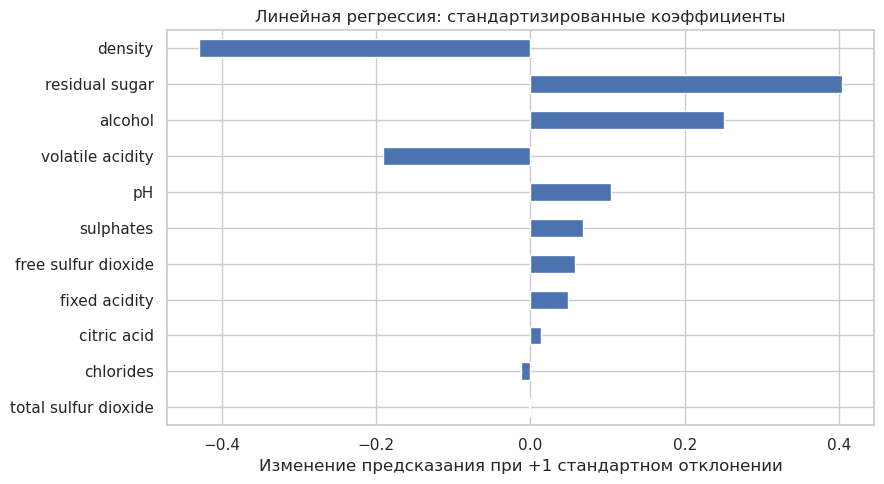

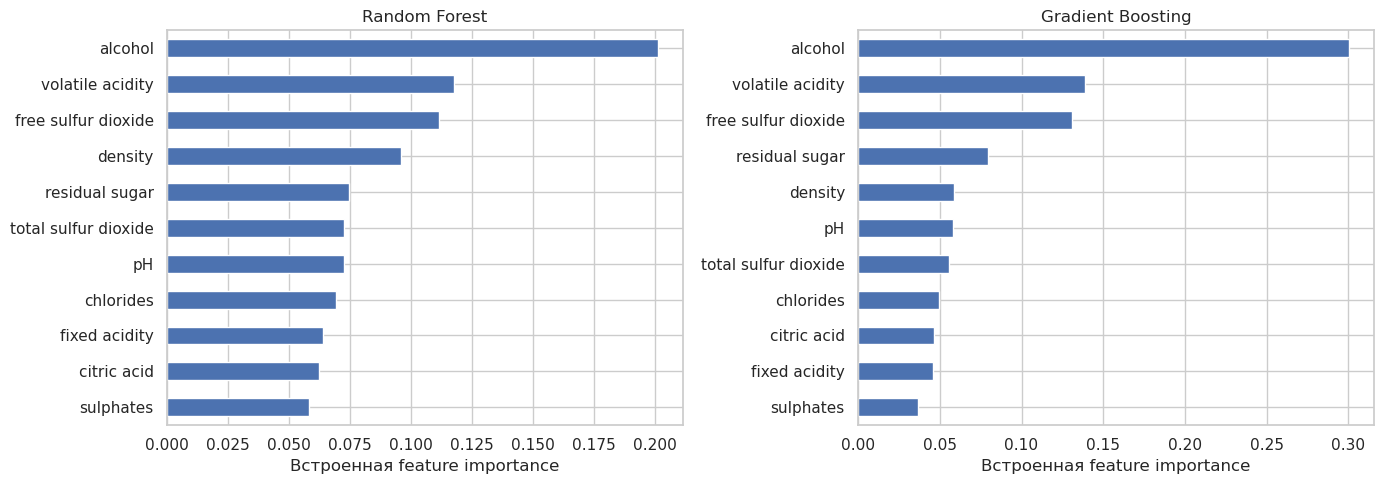

,Random Forest,Gradient Boosting
alcohol,0.2015,0.3006
volatile acidity,0.1177,0.1391
free sulfur dioxide,0.1113,0.1308
density,0.0959,0.0586
residual sugar,0.0748,0.0795
total sulfur dioxide,0.0726,0.0556
pH,0.0726,0.0579
chlorides,0.0692,0.0493
fixed acidity,0.0641,0.0459
citric acid,0.0621,0.0464


Топ-3 лес: ['alcohol', 'volatile acidity', 'free sulfur dioxide']
Топ-3 бустинг: ['alcohol', 'volatile acidity', 'free sulfur dioxide']


In [10]:
lin = fitted_models["Linear Regression"].named_steps["linearregression"]
coefs = pd.Series(lin.coef_, index=X.columns).sort_values(key=np.abs, ascending=False)
display(coefs.to_frame("Стандартизированный коэффициент").round(4))
coefs.iloc[::-1].plot.barh(figsize=(9,5),title="Линейная регрессия: стандартизированные коэффициенты")
plt.xlabel("Изменение предсказания при +1 стандартном отклонении");plt.tight_layout();plt.show()

fig, axes = plt.subplots(1,2,figsize=(14,5))
importance_series = {}
for ax, name in zip(axes,["Random Forest", "Gradient Boosting"]):
    imp = pd.Series(fitted_models[name].feature_importances_,index=X.columns).sort_values()
    importance_series[name] = imp
    imp.plot.barh(ax=ax,title=name)
    ax.set_xlabel("Встроенная feature importance")
plt.tight_layout();plt.show()
imp_compare = pd.DataFrame({k:v for k,v in importance_series.items()}).sort_values("Random Forest",ascending=False)
display(imp_compare.round(4))
print("Топ-3 лес:", importance_series["Random Forest"].sort_values(ascending=False).head(3).index.tolist())
print("Топ-3 бустинг:", importance_series["Gradient Boosting"].sort_values(ascending=False).head(3).index.tolist())

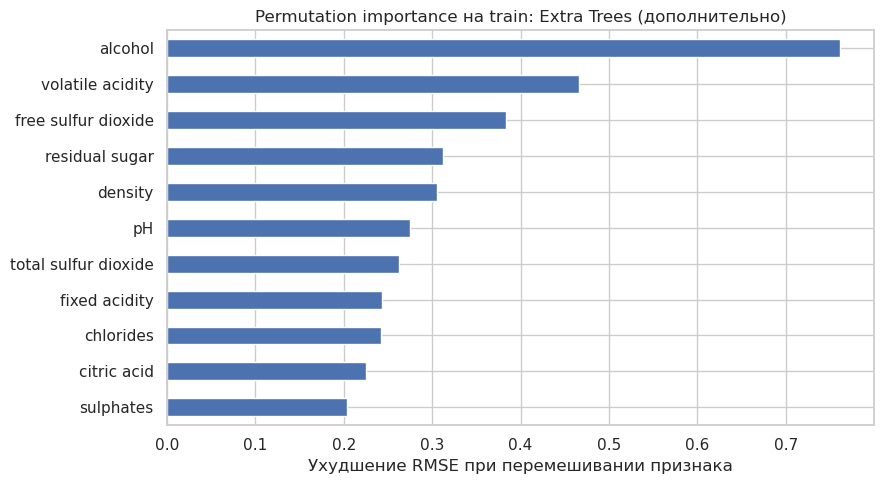

Вывод: важность означает полезность измерений для предсказания, не причинность.
Коррелированные признаки могут замещать друг друга, поэтому importance может занижать их индивидуальную роль.


In [11]:
# Пермутационная важность для заранее выбранной по CV модели, только на TRAIN
perm = permutation_importance(fitted_models[selected_name], X_train, y_train,
                              n_repeats=5, random_state=SEED,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
perm_imp.plot.barh(figsize=(9,5), title=f"Permutation importance на train: {selected_name}")
plt.xlabel("Ухудшение RMSE при перемешивании признака");plt.tight_layout();plt.show()
print("Вывод: важность означает полезность измерений для предсказания, не причинность.")
print("Коррелированные признаки могут замещать друг друга, поэтому importance может занижать их индивидуальную роль.")

### Почему feature importance ≠ причинное влияние?

В данных нет рандомизированного эксперимента, а признаки коррелируют друг с другом. `feature_importance` измеряет, насколько модель **использует** переменную для предсказаний; изменение химического показателя в реальном производстве не обязано изменять оценку именно на величину, которую предполагает модель.

## 7. Анализ ошибок выбранной по CV модели

Лучшей для подробного анализа считаем **модель с минимальным CV RMSE**, определённую до взгляда на тестовые метрики. Изучаем распределение остатков, экстремальные ошибки и качество для каждой истинной оценки.

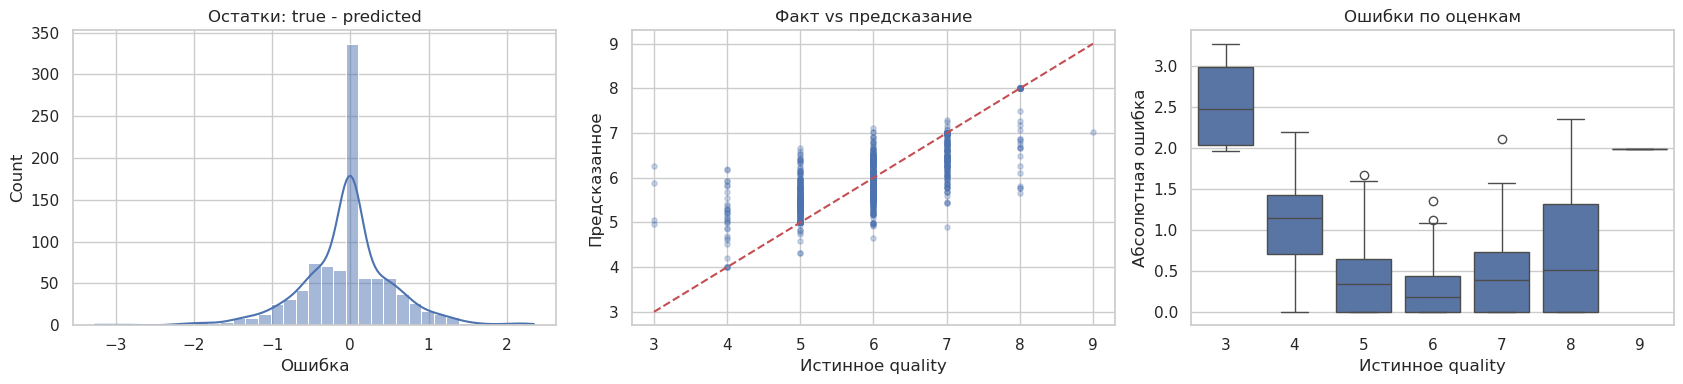

Самые крупные ошибки:


,quality_true,quality_pred,residual,absolute_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
1229,3,6.265,-3.265,3.265,8.3,0.33,0.42,1.15,0.033,18.0,96.0,0.991,3.20,0.32,12.4
3087,3,5.895,-2.895,2.895,6.1,0.20,0.34,9.50,0.041,38.0,201.0,0.995,3.14,0.44,10.1
1406,8,5.653,2.347,2.347,8.2,0.22,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5
17,8,5.773,2.227,2.227,6.2,0.66,0.48,1.20,0.029,29.0,75.0,0.989,3.33,0.39,12.8
20,8,5.773,2.227,2.227,6.2,0.66,0.48,1.20,0.029,29.0,75.0,0.989,3.33,0.39,12.8
1115,8,5.809,2.191,2.191,7.0,0.15,0.38,2.20,0.047,33.0,96.0,0.993,3.13,0.39,10.4
3770,4,6.187,-2.187,2.187,7.4,0.27,0.31,2.40,0.014,15.0,143.0,0.991,3.03,0.65,12.0
2116,4,6.169,-2.169,2.169,6.8,0.20,0.27,1.20,0.034,19.0,68.0,0.990,3.14,0.37,11.7
812,7,4.898,2.102,2.102,6.4,0.35,0.28,1.10,0.055,9.0,160.0,0.994,3.42,0.50,9.1
1688,3,5.056,-2.056,2.056,6.7,0.25,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4


,n,MAE,RMSE,mean_pred
quality_true,,,,
3,4,2.543,2.603,5.543
4,33,1.096,1.255,5.096
5,291,0.398,0.564,5.380
6,440,0.261,0.378,5.962
7,176,0.453,0.625,6.556
8,35,0.736,1.097,7.264
9,1,1.982,1.982,7.018


In [12]:
chosen_pred = test_predictions[selected_name]
err = y_test.to_numpy() - chosen_pred
abs_err = np.abs(err)
fig, axes = plt.subplots(1, 3, figsize=(17,4))
sns.histplot(err, bins=35, kde=True, ax=axes[0])
axes[0].set_title("Остатки: true - predicted")
axes[0].set_xlabel("Ошибка")
axes[1].scatter(y_test, chosen_pred, alpha=.27, s=14)
axes[1].plot([y.min(),y.max()],[y.min(),y.max()],"r--")
axes[1].set_xlabel("Истинное quality"); axes[1].set_ylabel("Предсказанное")
axes[1].set_title("Факт vs предсказание")
sns.boxplot(x=y_test.to_numpy(),y=abs_err,ax=axes[2])
axes[2].set_xlabel("Истинное quality");axes[2].set_ylabel("Абсолютная ошибка")
axes[2].set_title("Ошибки по оценкам")
plt.tight_layout();plt.show()

error_df = X_test.copy()
error_df.insert(0,"quality_true",y_test.to_numpy())
error_df.insert(1,"quality_pred",chosen_pred)
error_df.insert(2,"residual",err)
error_df.insert(3,"absolute_error",abs_err)
print("Самые крупные ошибки:")
display(error_df.nlargest(10,"absolute_error").round(3))
error_by_quality = (error_df.groupby("quality_true")
                    .agg(n=("absolute_error","size"),
                         MAE=("absolute_error","mean"),
                         RMSE=("residual",lambda z: np.sqrt(np.mean(np.square(z)))),
                         mean_pred=("quality_pred","mean")))
display(error_by_quality.round(3))
error_df.to_csv("wine_quality_test_errors.csv",index=False)

In [13]:
rare = y_train.value_counts().sort_values().head(2).index.tolist()
worst = error_df.nlargest(3, "absolute_error")
print("Самые редкие значения quality в train:", rare)
print("Наиболее крупные ошибки на объектах (индексы):", worst.index.tolist())
print("Объяснение: при редких оценках обучение преимущественно оптимизирует центральную массу примеров;")
print("предсказания моделей регрессии часто стягиваются к частым значениям. Нехватка переменных")
print("(вкус, аромат, происхождение, экспертная вариативность) тоже может повышать ошибку.")
print("Это возможные объяснения, но по наблюдательному датасету нельзя установить причину отдельного промаха.")

Самые редкие значения quality в train: [9, 3]
Наиболее крупные ошибки на объектах (индексы): [1229, 3087, 1406]
Объяснение: при редких оценках обучение преимущественно оптимизирует центральную массу примеров;
предсказания моделей регрессии часто стягиваются к частым значениям. Нехватка переменных
(вкус, аромат, происхождение, экспертная вариативность) тоже может повышать ошибку.
Это возможные объяснения, но по наблюдательному датасету нельзя установить причину отдельного промаха.


## 8. Итог

После выполнения всех ячеек получите:

1. Сравнение **Baseline / Linear Regression / Random Forest / Gradient Boosting**, а также опционально Extra Trees на единой тестовой выборке.
2. Разницу MAE и RMSE и интерпретацию для Wine Quality.
3. Коэффициенты стандартизированной линейной модели, две карты встроенной feature importance, пермутационную важность.
4. Графики и таблицу максимальных ошибок; анализ редких оценок.

**Ограничение:** открытая тестовая выборка в тетради — не скрытая тестовая выборка преподавателя. Нельзя гарантировать порог на неизвестном разделении. При повторном запуске с тем же `SEED` и версиями пакетов результаты воспроизводимы. Для исследования реальных причин изменения качества нужны эксперименты и дополнительные сведения о винах.

**Источник данных:** P. Cortez et al., *Wine Quality* (UCI Machine Learning Repository), https://doi.org/10.24432/C56S3T (CC BY 4.0).